# Detecção de Pneumonia em Raio-X de Tórax com ResNet18

Este notebook usa **PyTorch** para fazer o *fine-tuning* de uma **ResNet18 pré-treinada no ImageNet**, classificando radiografias de tórax em duas classes: **NORMAL** e **PNEUMONIA** (dataset *Chest X-Ray Pneumonia*, do Kaggle).

Etapas do projeto:
1. Imports e hiperparâmetros;
2. Download e carregamento dos dados (com *data augmentation* no treino);
3. Adaptação da rede, otimizador e função de perda;
4. Treino e validação por época;
5. Métricas por época: acurácia, recall e F1.

> **Observação:** a pasta `val/` original tem só 16 imagens, então **o conjunto de teste é usado como validação** (para escolher o melhor modelo e também para avaliar).

Antes de tudo, vamos fazer os imports e definir os hiperparâmetros:

In [1]:
# Implementação e treinamento da rede
import torch
from torch import nn, optim

# Carregamento de Dados e Modelos
from torch.utils.data import DataLoader
from torchvision import datasets, models
from torchvision import transforms

# Plots e análises
from sklearn.metrics import accuracy_score, recall_score, f1_score

import matplotlib.pyplot as plt
import numpy as np
import time, os

%matplotlib inline

# Configurando hiperparâmetros.
args = {
    'epoch_num': 4,      # Número de épocas.
    'lr': 3e-5,           # Taxa de aprendizado.
    'weight_decay': 1e-2, # Penalidade L2 (Regularização).
    'batch_size': 20,     # Tamanho do batch.
}



## GPU Cast

Para que o script funcione em ambientes com e sem GPU, definimos o dispositivo no início do código, com a verificação a seguir. Esse dispositivo será usado sempre que precisarmos enviar valores para a GPU, como os pesos da rede, os gradientes e a função de perda.

O método **`torch.cuda.is_available()`** retorna **True** se uma GPU compatível com CUDA estiver disponível e **False** caso contrário.

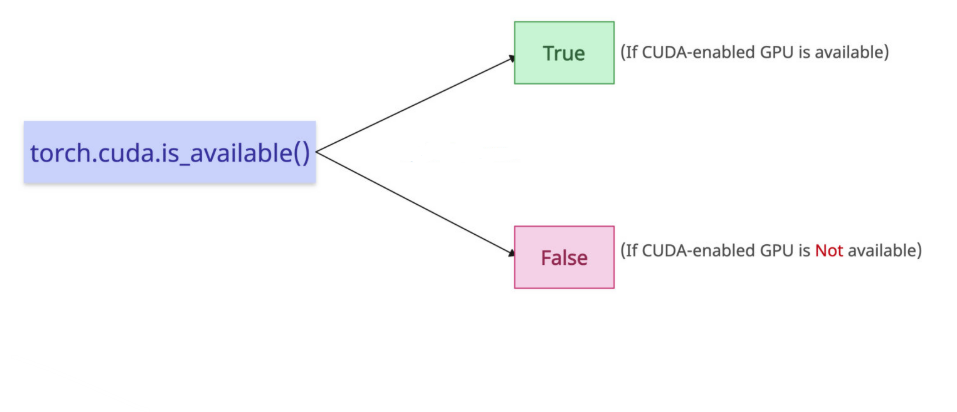

Treinar na CPU funciona, mas é muito mais lento. Se o tempo por época ficar muito alto, confira se o dispositivo impresso abaixo é `cuda`.

In [2]:
# Definindo dispositivo de hardware
if torch.cuda.is_available():
    args['device'] = torch.device('cuda')
else:
    args['device'] = torch.device('cpu')

print(args['device'])

cuda


## Baixando o dataset

Usamos o `kagglehub` para baixar o dataset.

As três células seguintes fazem o download, mostram o caminho dos arquivos e localizam a pasta que contém `train/` e `test/`. No final, conferem as classes e a quantidade de imagens de cada uma. Repare que o dataset é **desbalanceado**: há bem mais imagens de PNEUMONIA que de NORMAL.

In [3]:
import kagglehub
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.


In [4]:
print(path)

/kaggle/input/chest-xray-pneumonia


In [5]:
root = None
for dirpath, dirnames, _ in os.walk(path):
    if 'train' in dirnames and 'test' in dirnames:
        root = dirpath
        break
print(root)

 #Confere as classes e a quantidade de imagens
for split in ['train', 'test']:
    for classe in sorted(os.listdir(os.path.join(root, split))):
      pasta = os.path.join(root, split, classe)
      if os.path.isdir(pasta):
        print(split, classe, len(os.listdir(pasta)))

/kaggle/input/chest-xray-pneumonia/chest_xray
train NORMAL 1341
train PNEUMONIA 3875
test NORMAL 234
test PNEUMONIA 390


## Carregando Dados

Usamos dois pré-processamentos diferentes:

**Treino (`data_transform`)**, com *data augmentation*:
- `Resize((224, 224))`: todas as radiografias ficam com o mesmo tamanho e podem ser agrupadas em batches;
- `RandomHorizontalFlip()`: espelha a imagem aleatoriamente;
- `RandomRotation(10)`: gira a imagem em até ±10 graus;
- `ColorJitter(brightness=0.3, contrast=0.3)`: varia brilho e contraste;
- `Normalize` com a média e o desvio padrão do ImageNet.

**Teste/validação (`test_transform`)**: apenas `Resize` e `Normalize`, **sem augmentation**, para medir o modelo em imagens reais.

A normalização com os valores do ImageNet é necessária porque a ResNet18 foi pré-treinada com esse padrão.

As transformações aleatórias são sorteadas a cada vez que uma imagem é carregada. Isso gera variações diferentes a cada época, sem alterar os arquivos originais.

In [6]:
data_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),   # nova linha: gira até ±10 graus
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])


train_set = datasets.ImageFolder(os.path.join(root, 'train'),
                      transform= data_transform) # transformação composta

test_set = datasets.ImageFolder(os.path.join(root, 'test'),
                      transform= test_transform) # usado como validação

O `datasets.ImageFolder` varre as pastas dentro dos diretórios de treino e teste (NORMAL e PNEUMONIA) e atribui automaticamente um índice inteiro a cada pasta, seguindo a **ordem alfabética** dos nomes:

- a pasta que vem primeiro alfabeticamente recebe o valor **0** (NORMAL);
- a pasta seguinte recebe o valor **1** (PNEUMONIA).

A célula abaixo mostra esse mapeamento e o formato de uma imagem: `[canais, altura, largura]`.

In [7]:
print(train_set.class_to_idx)
print("")

print(train_set[0][0].shape)

{'NORMAL': 0, 'PNEUMONIA': 1}

torch.Size([3, 224, 224])


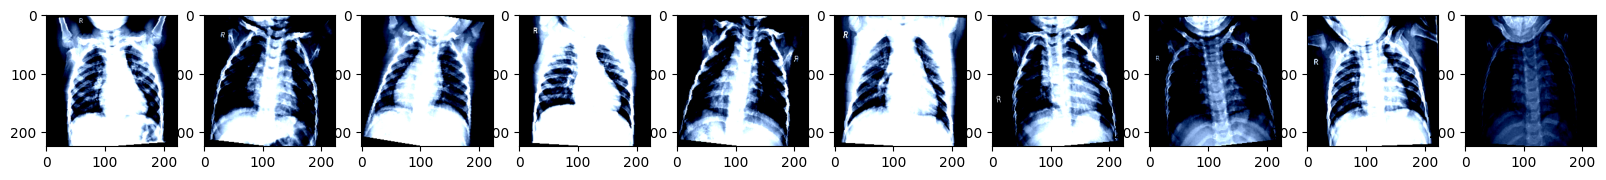

In [8]:
fig, axs = plt.subplots(1,10, figsize=(20, 2))
for i in range(10):
  data, label = train_set[i]
  axs[i].imshow(data.permute((1,2,0)))
  axs[i].axis('on')

### DataLoader

O `DataLoader` gerencia o carregamento de dados para o treinamento de redes neurais, oferecendo:

* Separação dos dados em batches;
* Embaralhamento dos dados (`shuffle`);
* Carregamento em paralelo com vários processos, por meio do parâmetro `num_workers` (aqui usamos o valor padrão).

A leitura de arquivos costuma ser um gargalo de tempo no treino, e o carregamento em paralelo ajuda a reduzir os períodos ociosos da GPU.

In [9]:
train_loader = DataLoader(train_set,
                          batch_size=args['batch_size'],
                          shuffle=True)

test_loader = DataLoader(test_set,
                          batch_size=args['batch_size'],
                          shuffle=True)

O objeto retornado é um **iterador**: pode ser usado em loops, mas não suporta indexação.

A célula abaixo mostra o formato de um batch de imagens, `[batch_size, 3, 224, 224]`, e dos rótulos, `[batch_size]`.

In [10]:
for batch in train_loader:
    dado, rotulo = batch
    print(dado.size(), rotulo.size())

    break

torch.Size([20, 3, 224, 224]) torch.Size([20])


## Adaptando a Rede (ResNet18)

---

# Fine-Tuning

O objetivo é aproveitar um modelo já bem treinado e sua capacidade de generalizar para dados que nunca viu.

O aprendizado é hierárquico: as camadas iniciais (em vermelho na imagem) aprendem características de baixo nível, como bordas e quinas, que servem para vários datasets. Já as camadas finais (em amarelo na imagem) aprendem características mais específicas do dataset de treino, e são elas que **adaptamos** ao nosso problema.

Neste projeto seguimos dois passos:
* Carregar a **ResNet18 com pesos do ImageNet**;
* **Substituir a camada final de classificação** (`fc`) por uma nova, com 2 saídas.

Nenhuma camada é congelada: a rede inteira é treinada, com uma taxa de aprendizado baixa para não destruir o que o modelo já aprendeu.

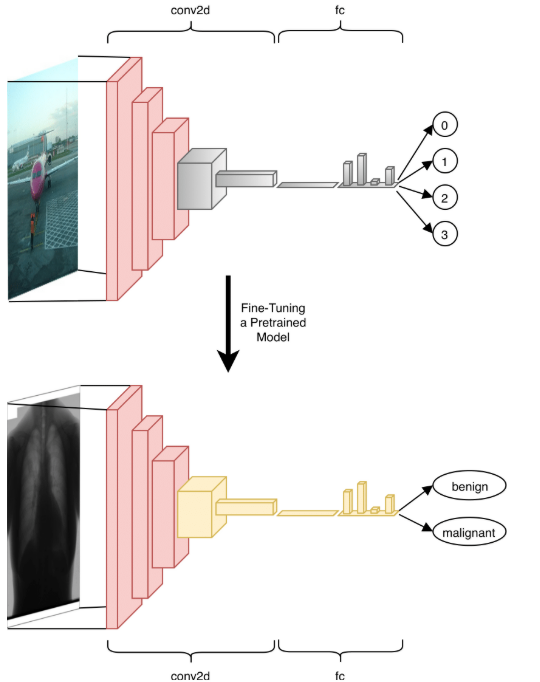

---

In [11]:
# ResNet18 pré-treinada no ImageNet
net = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
print(net)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 190MB/s]

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

Vamos redefinir a camada de classificação (`net.fc`), criando uma nova camada com as dimensões adequadas ao nosso desafio:

* O modelo original classifica as 1.000 classes do ImageNet: <br>
```nn.Linear(512, 1000)```
* Nossa adaptação classifica 2 classes (NORMAL e PNEUMONIA): <br>
```nn.Linear(512, 2)```


In [12]:
# Troca a última camada (1000 classes -> 2 classes)
net.fc = nn.Linear(net.fc.in_features, 2)

net = net.to(args['device'])
print(net)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

## Definindo o otimizador

Usamos o **AdamW**, que atualiza todos os parâmetros da rede com uma **única taxa de aprendizado** (`lr`) e aplica o *weight decay* (regularização) diretamente nos pesos, de forma separada do gradiente.

Os valores de `lr` e `weight_decay` vêm do hiperparâmetros `args`, definido no início do notebook.

In [13]:
optimizer = optim.AdamW(net.parameters(), lr=args['lr'], weight_decay=args['weight_decay'])

### Definindo a **função de perda** (função objetivo, critério ou *loss*)

O primeiro passo é instanciar a função de perda. Trata-se de um problema de classificação com 2 classes, então a função recomendada é a *Cross Entropy*, que no PyTorch se chama `CrossEntropyLoss`.

Como o dataset é desbalanceado, passamos **pesos por classe** (`weight`), inversamente proporcionais à quantidade de imagens de cada uma. Assim, errar uma radiografia da classe menos frequente (NORMAL) pesa mais na loss, e o modelo deixa de aprender o atalho de responder sempre "pneumonia".

**Assim como a rede, a função de perda também deve ser enviada para a GPU.**

#### **DESBALACEAMENTO**

O dataset é desbalanceado (1341 imagens NORMAL contra 3875 PNEUMONIA), então damos mais peso aos erros da classe menos frequente.

- `np.bincount(train_set.targets)`: conta as imagens de cada classe, resultando em `[1341, 3875]`;
- `counts.sum() / (classes * counts)`: calcula o peso de cada classe, inversamente proporcional à sua quantidade (NORMAL ≈ 1,94 e PNEUMONIA ≈ 0,67);
- `CrossEntropyLoss(weight=pesos)`: multiplica o erro de cada imagem pelo peso da sua classe, e errar uma radiografia NORMAL passa a pesar cerca de 3 vezes mais;
- `.to(args['device'])`: envia a função de perda e os pesos para a GPU.

In [14]:
counts = np.bincount(train_set.targets)
pesos = torch.tensor(counts.sum() / (2 * counts), dtype=torch.float)
criterion = nn.CrossEntropyLoss(weight=pesos).to(args['device']) # Cast do dado na GPU

## Treino e Validação

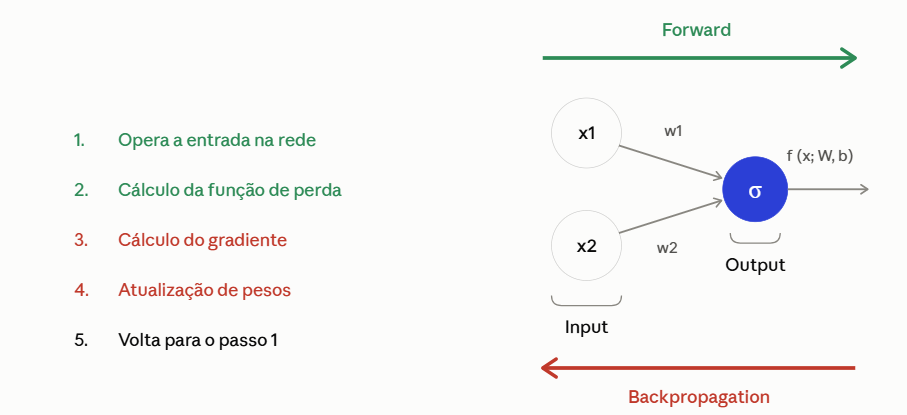

### 1. **Forward (ResNet18)**

É o fluxo das imagens de radiografia pelas camadas da ResNet18, da entrada até as predições de classificação.

- A entrada deve ser um dado do tipo Tensor.
- A camada convolucional espera uma entrada com as dimensões: B x C x H x W (batch, canais, altura, largura).

### 2. **Backpropagation**

É a propagação do erro para trás, onde os gradientes são calculados. A **taxa de aprendizado** define o tamanho do passo dado na atualização dos pesos, equilibrando velocidade e estabilidade do aprendizado.

### 3. **Manipulação de batches com `np.concatenate`**

Usamos `np.concatenate` para juntar os resultados de todos os batches em um único vetor, o que também funciona para o último batch, que geralmente é menor que os demais.

## Treinamento

Passo a passo do fluxo de treinamento:

- Iterar nas épocas;
- Iterar nos *batches*;
- Realizar o *cast* dos dados para o dispositivo de hardware;
- Executar o *forward* na rede e calcular a *loss*;
- Calcular os gradientes e atualizar os pesos.

Esse conjunto de passos é o processo iterativo de otimização de uma rede neural. A validação, por outro lado, consiste apenas em aplicar a rede a dados que ela não usou para atualizar os pesos, para estimar a qualidade do modelo em situações reais.

In [15]:
def train(train_loader, net, epoch):

  # Training mode
  net.train()

  start = time.time()

  epoch_loss  = []
  pred_list, rotulo_list = [], []
  for k, batch in enumerate(train_loader):
    print('\r--{0}/{1}--'.format(k, len(train_loader)), end='', flush=True)
    dado, rotulo = batch

    # Cast do dado na GPU
    dado = dado.to(args['device'])
    rotulo = rotulo.to(args['device'])

    # Forward
    ypred = net(dado) # Alimentar os dados para a rede
    loss = criterion(ypred, rotulo) # Calcular a função de custo
    epoch_loss.append(loss.cpu().data)

    _, pred = torch.max(ypred, axis=1)
    pred_list.append(pred.cpu().numpy())
    rotulo_list.append(rotulo.cpu().numpy())

    # Backpropagation
    optimizer.zero_grad()
    loss.backward() # Calcular o gradiente
    optimizer.step() # Atualizar os pesos

  epoch_loss = np.asarray(epoch_loss)
  pred_list  = np.concatenate(pred_list)
  rotulo_list  = np.concatenate(rotulo_list)

  acc = accuracy_score(pred_list, rotulo_list)

  end = time.time()
  print('\n#################### Train ####################')
  print('Epoch %d, Loss: %.4f +/- %.4f, Acc: %.2f, Time: %.2f' % (epoch, epoch_loss.mean(), epoch_loss.std(), acc*100, end-start))

  return epoch_loss.mean()

## Validação

Para essa etapa, o PyTorch oferece dois recursos:

- **`model.eval()`:** altera o comportamento de certas camadas durante o *forward*, como *Dropout* e *Batch Normalization* (a ResNet18 usa Batch Normalization).

- **`with torch.no_grad()`:** gerenciador de contexto que desabilita o cálculo e o armazenamento de gradientes, economizando tempo e memória. Todo o código de validação deve ser executado dentro desse contexto.

In [16]:
def validate(test_loader, net, epoch):

  # Evaluation mode
  net.eval()

  start = time.time()

  epoch_loss  = []
  pred_list, rotulo_list = [], []
  with torch.no_grad():
    for k, batch in enumerate(test_loader):

      print('\r--{0}/{1}--'.format(k, len(test_loader)), end='', flush=True)
      dado, rotulo = batch

      # Cast do dado na GPU
      dado = dado.to(args['device'])
      rotulo = rotulo.to(args['device'])

      # Forward
      ypred = net(dado) # Alimentar os dados para a rede
      loss = criterion(ypred, rotulo) # Calcular a função de custo
      epoch_loss.append(loss.cpu().data)

      _, pred = torch.max(ypred, axis=1)
      pred_list.append(pred.cpu().numpy())
      rotulo_list.append(rotulo.cpu().numpy())

  epoch_loss = np.asarray(epoch_loss)
  pred_list  = np.concatenate(pred_list)
  rotulo_list  = np.concatenate(rotulo_list)

  acc = accuracy_score(pred_list, rotulo_list)
  rec = recall_score(rotulo_list, pred_list, average=None)
  f1  = f1_score(rotulo_list, pred_list, average=None)

  end = time.time()
  print('\n********** Validate **********')
  print('Epoch %d, Loss: %.4f +/- %.4f, Acc: %.2f, Time: %.2f' % (epoch, epoch_loss.mean(), epoch_loss.std(), acc*100, end-start))
  print('Recall -> NORMAL: %.2f, PNEUMONIA: %.2f' % (rec[0]*100, rec[1]*100))
  print('F1     -> NORMAL: %.2f, PNEUMONIA: %.2f\n' % (f1[0]*100, f1[1]*100))

  return epoch_loss.mean()

In [17]:
train_losses, test_losses = [], []
for epoch in range(args['epoch_num']):

  # Train
  train_losses.append(train(train_loader, net, epoch))

  # Validate
  test_losses.append(validate(test_loader, net, epoch))



--260/261--
#################### Train ####################
Epoch 0, Loss: 0.1652 +/- 0.1451, Acc: 93.92, Time: 133.02
--31/32--
********** Validate **********
Epoch 0, Loss: 0.4579 +/- 0.3041, Acc: 89.10, Time: 13.89
Recall -> NORMAL: 72.65, PNEUMONIA: 98.97
F1     -> NORMAL: 83.33, PNEUMONIA: 91.90

--260/261--
#################### Train ####################
Epoch 1, Loss: 0.0907 +/- 0.0963, Acc: 96.64, Time: 99.07
--31/32--
********** Validate **********
Epoch 1, Loss: 0.5336 +/- 0.3548, Acc: 89.74, Time: 14.33
Recall -> NORMAL: 75.21, PNEUMONIA: 98.46
F1     -> NORMAL: 84.62, PNEUMONIA: 92.31

--260/261--
#################### Train ####################
Epoch 2, Loss: 0.0702 +/- 0.0803, Acc: 97.68, Time: 98.83
--31/32--
********** Validate **********
Epoch 2, Loss: 0.5390 +/- 0.3864, Acc: 90.22, Time: 10.82
Recall -> NORMAL: 74.79, PNEUMONIA: 99.49
F1     -> NORMAL: 85.16, PNEUMONIA: 92.71

--260/261--
#################### Train ####################
Epoch 3, Loss: 0.0556 +/- 0.0653,